BEFORE BIT-FLIP (|0⟩ State):


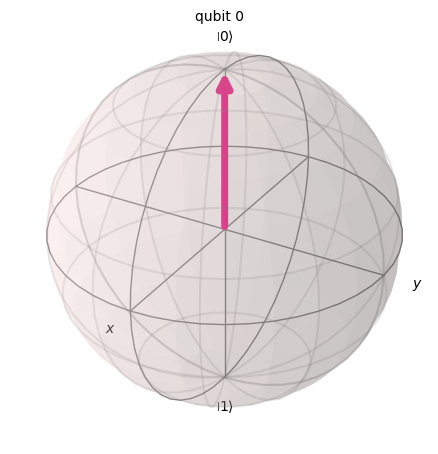

AFTER BIT-FLIP (|1⟩ State):


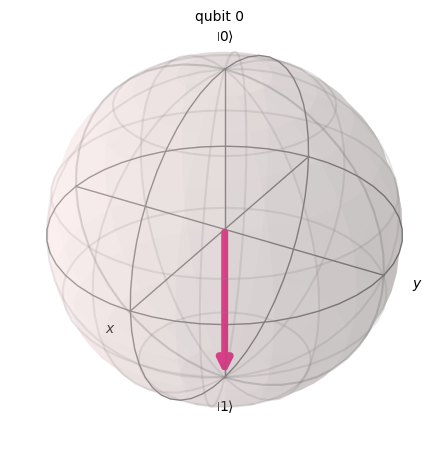

In [7]:
'''
To visualize bit flip
'''
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# 1. BEFORE (Qubit initialized to |0⟩)
qc_before = QuantumCircuit(1)
# Stays at default ground state |0⟩
state_before = Statevector.from_instruction(qc_before)

# 2. AFTER (Qubit suffers an accidental bit-flip X error)
qc_after = QuantumCircuit(1)
qc_after.x(0) # Injected bit-flip error
state_after = Statevector.from_instruction(qc_after)


print("BEFORE BIT-FLIP (|0⟩ State):")
display(plot_bloch_multivector(state_before))

print("AFTER BIT-FLIP (|1⟩ State):")
display(plot_bloch_multivector(state_after))

BEFORE BIT-FLIP (|+⟩ State):


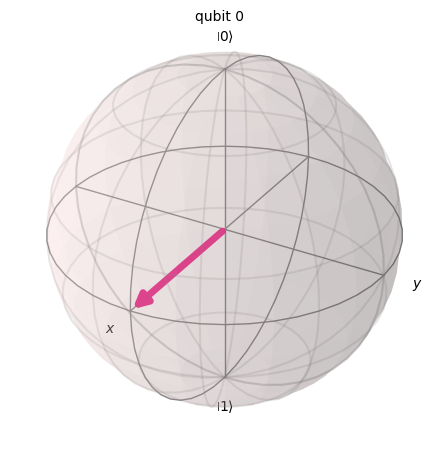

AFTER BIT-FLIP :


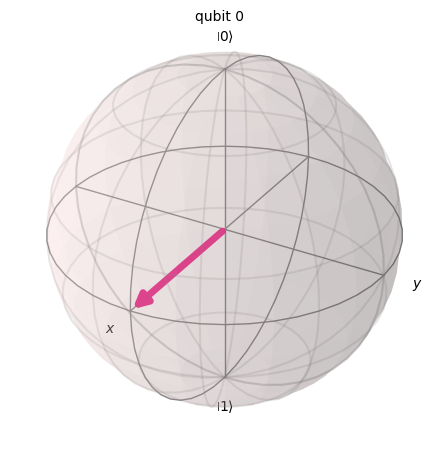

In [9]:
'''
Visualize bit flip in superposition
'''
# 1. Start in superposition (|Hadamard applied)
qc_before = QuantumCircuit(1)
qc_before.h(0)
state_before = Statevector.from_instruction(qc_before)

# 2. AFTER (Qubit suffers an accidental bit-flip X error)
qc_after = QuantumCircuit(1)
qc_after.h(0)
qc_after.x(0) # Injected bit-flip error
state_after = Statevector.from_instruction(qc_after)


print("BEFORE BIT-FLIP (|+⟩ State):")
display(plot_bloch_multivector(state_before))

print("AFTER BIT-FLIP:")
display(plot_bloch_multivector(state_after))


BEFORE (Ideal City Plot):
AFTER (Noisy City Plot):


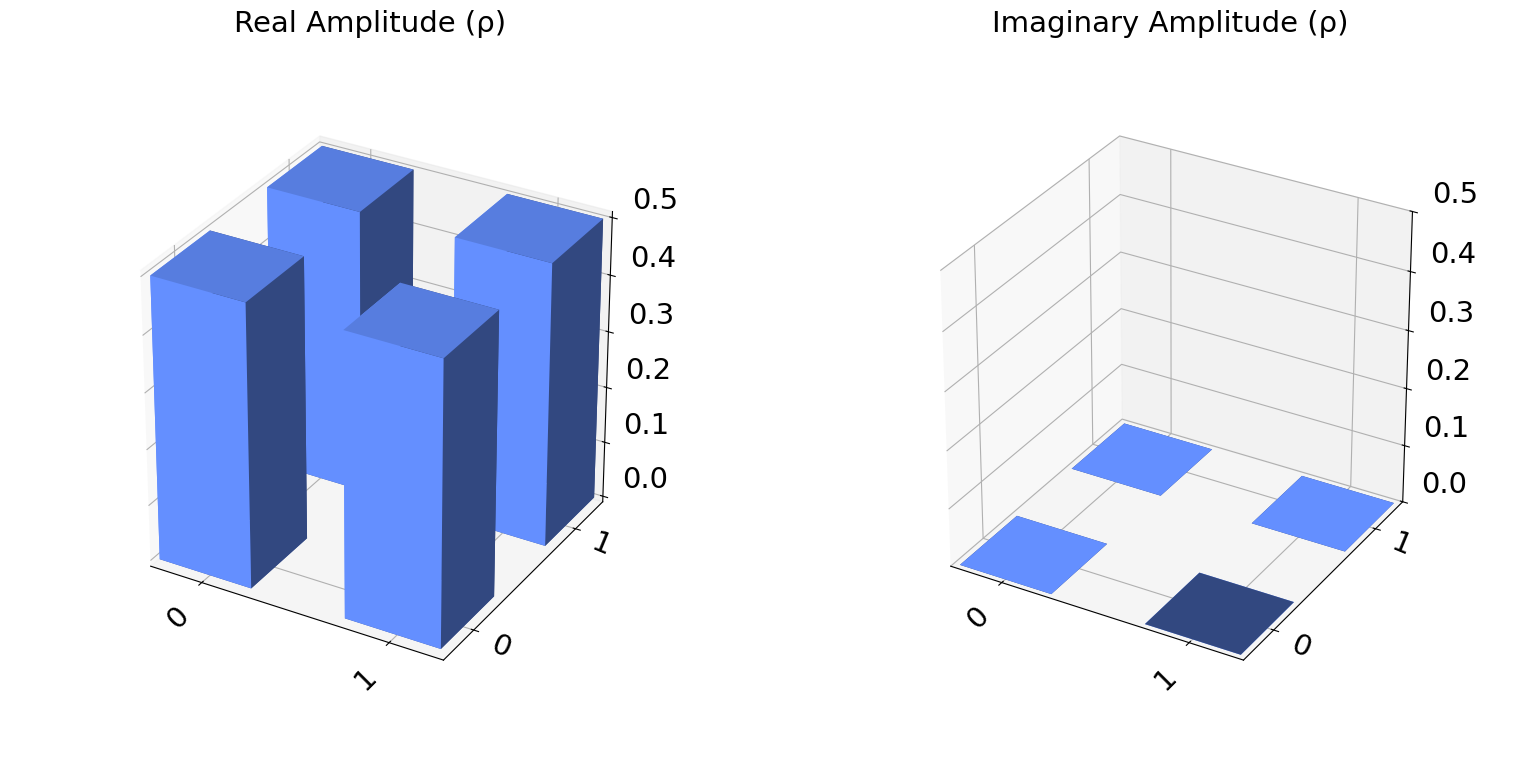

In [10]:
# Ideal Bell State Matrix
print("BEFORE (Ideal City Plot):")
state_before.draw('city')
# Noisy Bell State Matrix (Bit-Flipped)
print("AFTER (Noisy City Plot):")
state_after.draw('city')

BEFORE BIT NOISE (|Φ+⟩):
AFTER BIT NOISE (|Ψ+⟩):


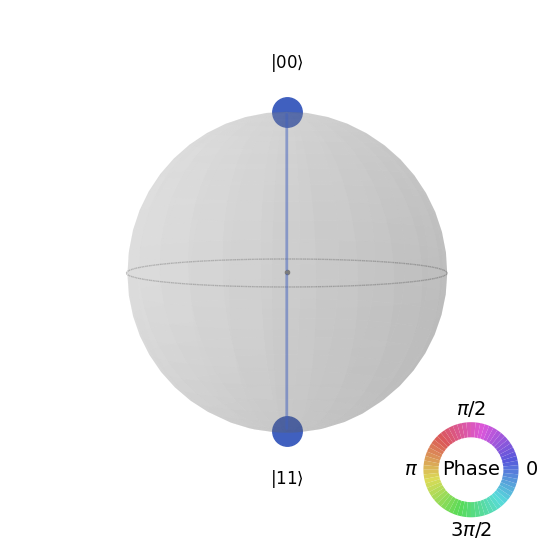

In [4]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# 1. BEFORE (Ideal Bell State: |Φ+⟩)
qc_before = QuantumCircuit(2)
qc_before.h(0)
qc_before.cx(0, 1)
state_before = Statevector.from_instruction(qc_before)

# 2. AFTER (Noisy Bell State with Bit-Flip: |Ψ+⟩)
qc_after = QuantumCircuit(2)
qc_after.h(0)
qc_after.x(0) # Injected accidental bit-flip (X gate) error on qubit 0
qc_after.cx(0, 1)
state_after = Statevector.from_instruction(qc_after)

# Before Bit Noise (Ideal)
print("BEFORE BIT NOISE (|Φ+⟩):")
state_before.draw('qsphere')
# After Bit Noise (Corrupted)
print("AFTER BIT NOISE (|Ψ+⟩):")
state_after.draw('qsphere')

BEFORE (Ideal City Plot):
AFTER (Noisy City Plot):


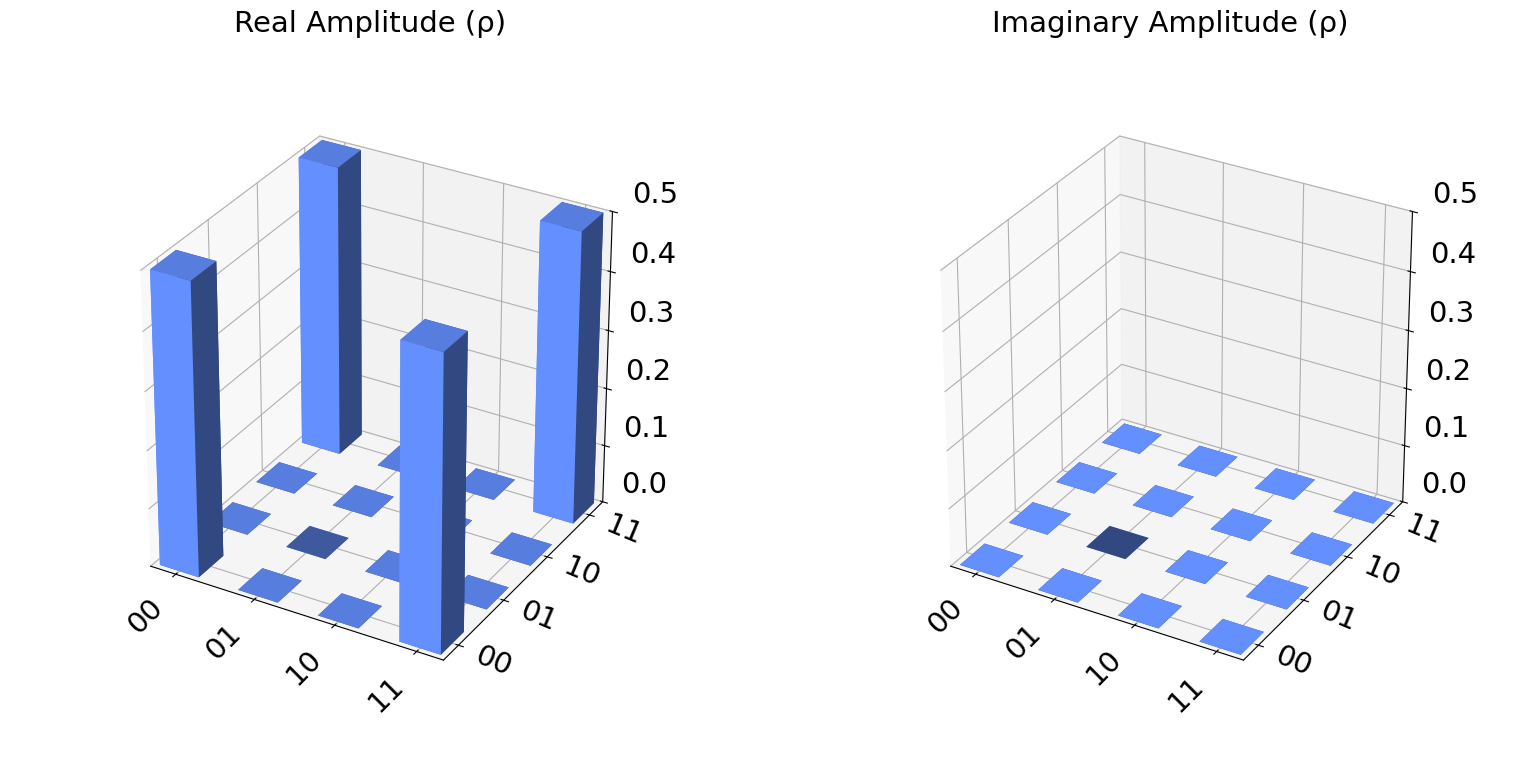

In [5]:
# Ideal Bell State Matrix
print("BEFORE (Ideal City Plot):")
state_before.draw('city')
# Noisy Bell State Matrix (Bit-Flipped)
print("AFTER (Noisy City Plot):")
state_after.draw('city')

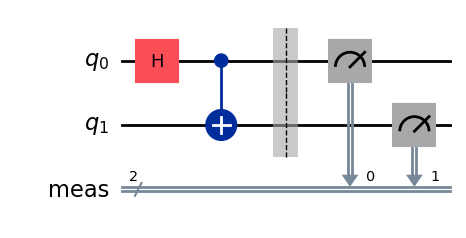

In [1]:
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error

# Build your standard Bell Circuit
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

# Define custom quantum errors
p_error = 0.05  # 5% chance of an error occurring
# simulate the bit flip error
error_gate1 = pauli_error([('X', p_error), ('I', 1 - p_error)])
# tensor the errors together to cover both qubits - necessary for 2 qubits error
error_gate2 = error_gate1.tensor(error_gate1)

# Create the Noise Model and assign errors to specific gates
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(error_gate1, ["h"])   # Apply to H gate
noise_model.add_all_qubit_quantum_error(error_gate2, ["cx"])  # Apply to CNOT gate


qc.draw(output="mpl")

Noisy Measurement Counts: {'01': 47, '10': 45, '00': 451, '11': 481}


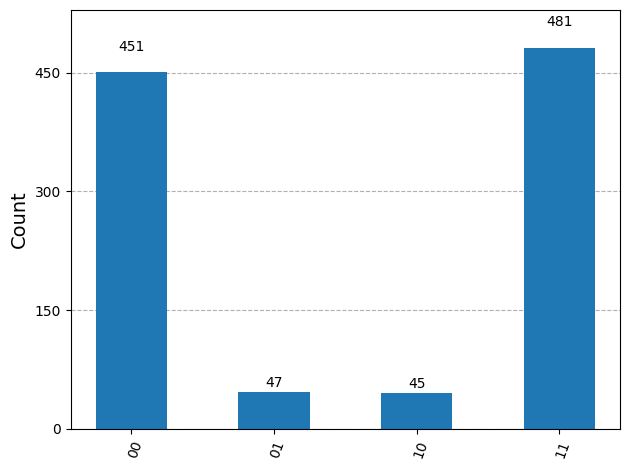

In [2]:

backend = AerSimulator(noise_model=noise_model)
pm = generate_preset_pass_manager(backend=backend, optimization_level=1) # Transpile the circuit to the simulator's basis gates
isa_circuit = pm.run(qc)

# Run the noisy simulation
job = backend.run(isa_circuit, shots=1024)
noisy_counts = job.result().get_counts()

print("Noisy Measurement Counts:", noisy_counts)
plot_histogram(noisy_counts)